# Exploratory Data Analysis: Assessments 1 to 9

**VIJAY V S · 23BDS0264**

This Python notebook recreates the main methods and outcomes from the nine R submissions. Run it from top to bottom in Google Colab. The Texas housing CSV is loaded once (about 0.5 MB); AirPassengers and mtcars are included directly. Standard Colab libraries are sufficient.

Plots and printed tables are kept compact for a screen recording. Clustering labels and ARIMA estimates can differ slightly from R because the libraries use different implementations.

## Setup: load the shared Texas housing data

In [1]:
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/txhousing.csv"
with urllib.request.urlopen(url, timeout=20) as response:
    tx = pd.read_csv(response)

tx = tx.drop(columns="rownames")
tx["period"] = pd.cut(tx["year"], [1999, 2004, 2009, 2015],
                      labels=["2000-04", "2005-09", "2010-15"])
tx["quarter"] = "Q" + ((tx["month"] - 1) // 3 + 1).astype(str)
print(f"Texas housing: {len(tx):,} rows, {tx['city'].nunique()} cities")
print("Main columns:", ", ".join(tx.columns[:9]))


Texas housing: 8,602 rows, 46 cities
Main columns: city, year, month, sales, volume, median, listings, inventory, date


## Assessment 1: data joins and normalization

Append product rows, join product details to locations, and put numeric values on comparable scales.

In [2]:
products = pd.DataFrame({
    "ProductID": [1, 2, 3, 4],
    "Product": ["shirt", "trousers", "socks", "shoes"],
    "Price": [1800, 2500, 500, 3200]
})
locations = pd.DataFrame({
    "ProductID": [1, 2, 3, 5],
    "City": ["Chennai", "Chennai", "Bengaluru", "Delhi"]
})
new_products = pd.DataFrame({
    "ProductID": [6, 7],
    "Product": ["jacket", "bag"],
    "Price": [4200, 2800]
})
appended = pd.concat([products, new_products], ignore_index=True)
print("Rows after appending:", len(appended))
for join_type in ["inner", "left", "right", "outer"]:
    result = products.merge(locations, on="ProductID", how=join_type)
    print(f"{join_type.title():5s} join: {len(result)} rows")

values = np.array([264, 2500, 1800, 4200, 3100, 1500, 4900, 2200, 3700, 2800])
unit = (values - values.min()) / (values.max() - values.min())
scaled = pd.DataFrame({
    "Original": values,
    "Range 0 to 1": unit,
    "Range -1 to 1": 2 * unit - 1,
    "Z score": (values - values.mean()) / values.std(ddof=1),
    "Decimal scaling": values / 10000
})
print(scaled.round(2).to_string(index=False))


Rows after appending: 6
Inner join: 3 rows
Left  join: 4 rows
Right join: 4 rows
Outer join: 5 rows
 Original  Range 0 to 1  Range -1 to 1  Z score  Decimal scaling
      264          0.00          -1.00    -1.78             0.03
     2500          0.48          -0.04    -0.14             0.25
     1800          0.33          -0.34    -0.66             0.18
     4200          0.85           0.70     1.10             0.42
     3100          0.61           0.22     0.30             0.31
     1500          0.27          -0.47    -0.88             0.15
     4900          1.00           1.00     1.62             0.49
     2200          0.42          -0.16    -0.36             0.22
     3700          0.74           0.48     0.74             0.37
     2800          0.55           0.09     0.08             0.28


**Outcome:** joins retain different records depending on the join type. Min-max scaling puts every value between 0 and 1; a z score describes distance from the average.

## Assessment 2: inspect and handle missing values

Review the dataset, then fill missing numeric values in a separate cleaned copy.

In [3]:
numeric_columns = ["sales", "volume", "median", "listings", "inventory"]
print("Shape:", tx.shape)
print("Missing values by column:")
print(tx[numeric_columns].isna().sum().to_string())
print("Duplicate rows:", tx.duplicated().sum())
print(tx[numeric_columns].describe().loc[["count", "mean", "50%"]].round(1).to_string())

clean = tx.copy()
clean[numeric_columns] = clean[numeric_columns].fillna(clean[numeric_columns].median())
clean = clean.drop_duplicates()
print("Rows after cleaning:", len(clean))
print("Missing numeric values after cleaning:", clean[numeric_columns].isna().sum().sum())


Shape: (8602, 11)
Missing values by column:
sales         568
volume        568
median        616
listings     1424
inventory    1467
Duplicate rows: 0
        sales       volume    median  listings  inventory
count  8034.0       8034.0    7986.0    7178.0     7135.0
mean    549.6  106858620.8  128131.4    3216.9        7.2
50%     169.0   22986824.0  123800.0    1283.0        6.2
Rows after cleaning: 8602
Missing numeric values after cleaning: 0


**Outcome:** the source has 8,602 records. Some housing measurements are missing, so later analyses either use complete rows or explicitly fill values.

## Assessment 3: outliers and simple distributions

Use the interquartile range (IQR) to flag unusually high or low sales, then view the distribution.

Sales median: 169; mean: 549.6
IQR outliers: 899 of 8,034 nonmissing sales values
Five cities with the most records:
city
Abilene      187
Amarillo     187
Arlington    187
Austin       187
Bay Area     187


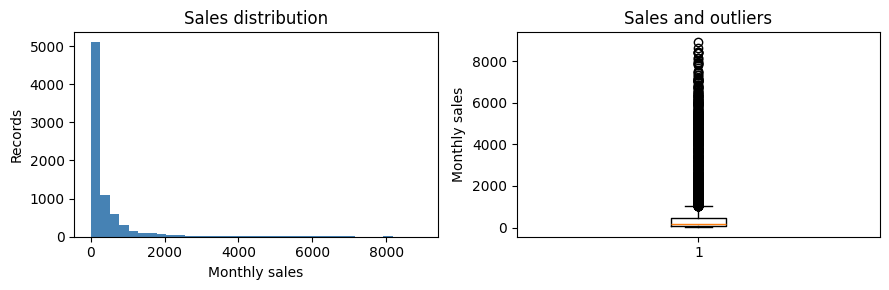

In [4]:
sales = tx["sales"].dropna()
q1, q3 = sales.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = sales[(sales < low) | (sales > high)]
print(f"Sales median: {sales.median():.0f}; mean: {sales.mean():.1f}")
print(f"IQR outliers: {len(outliers):,} of {len(sales):,} nonmissing sales values")
print("Five cities with the most records:")
print(tx["city"].value_counts().head().to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(sales, bins=35, color="steelblue")
axes[0].set(title="Sales distribution", xlabel="Monthly sales", ylabel="Records")
axes[1].boxplot(sales)
axes[1].set(title="Sales and outliers", ylabel="Monthly sales")
plt.tight_layout()
plt.show()


**Outcome:** the mean is much larger than the median, and the long right tail contains high-sales observations.

## Assessment 4: bivariate relationships

Compare two variables at a time with grouped counts, a scatter plot, a trend, and correlations.

Correlation with sales:
sales        1.000
volume       0.981
median       0.345
listings     0.921
inventory   -0.193


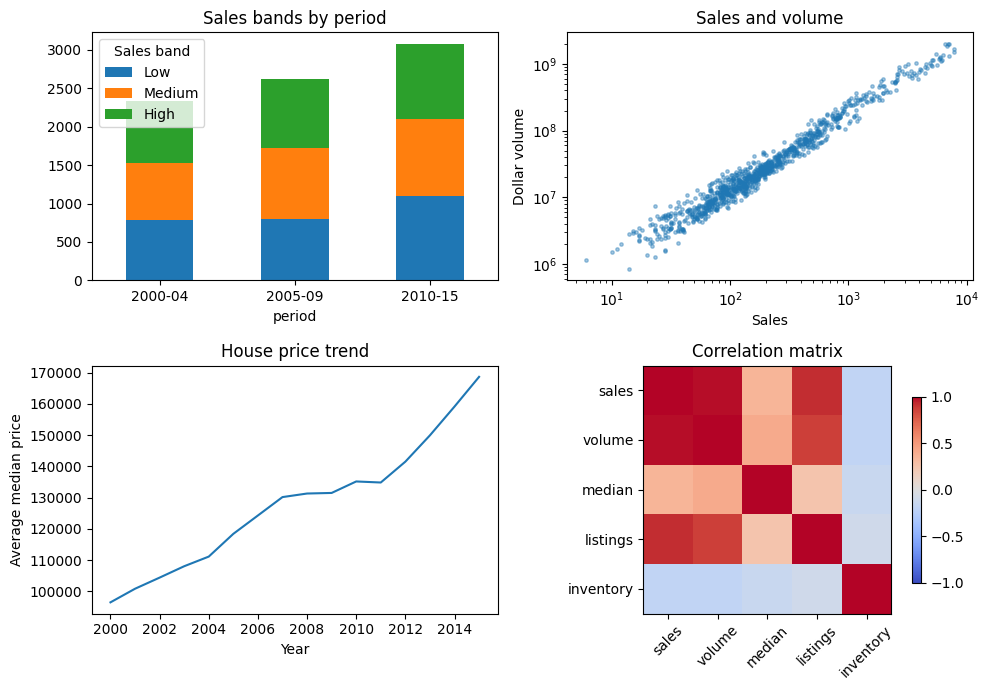

In [5]:
correlations = tx[numeric_columns].corr()
print("Correlation with sales:")
print(correlations["sales"].round(3).to_string())

sales_band = pd.qcut(tx["sales"], 3, labels=["Low", "Medium", "High"])
counts = pd.crosstab(tx["period"], sales_band)
sample = tx[["sales", "volume"]].dropna().sample(1000, random_state=42)
yearly_price = tx.groupby("year")["median"].mean()

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
counts.plot.bar(stacked=True, ax=axes[0, 0], title="Sales bands by period", rot=0)
axes[0, 0].legend(title="Sales band")
axes[0, 1].scatter(sample["sales"], sample["volume"], s=6, alpha=0.4)
axes[0, 1].set(xscale="log", yscale="log", xlabel="Sales",
               ylabel="Dollar volume", title="Sales and volume")
axes[1, 0].plot(yearly_price.index, yearly_price.values)
axes[1, 0].set(xlabel="Year", ylabel="Average median price",
               title="House price trend")
im = axes[1, 1].imshow(correlations, vmin=-1, vmax=1, cmap="coolwarm")
axes[1, 1].set_xticks(range(5), numeric_columns, rotation=45)
axes[1, 1].set_yticks(range(5), numeric_columns)
axes[1, 1].set_title("Correlation matrix")
fig.colorbar(im, ax=axes[1, 1], shrink=0.75)
plt.tight_layout()
plt.show()


**Outcome:** sales and dollar volume move together strongly. House prices also rise over the years in this dataset.

## Assessment 5: multivariate analysis

Show several variables in the same plot, then use scatter-matrix and parallel-coordinate views.

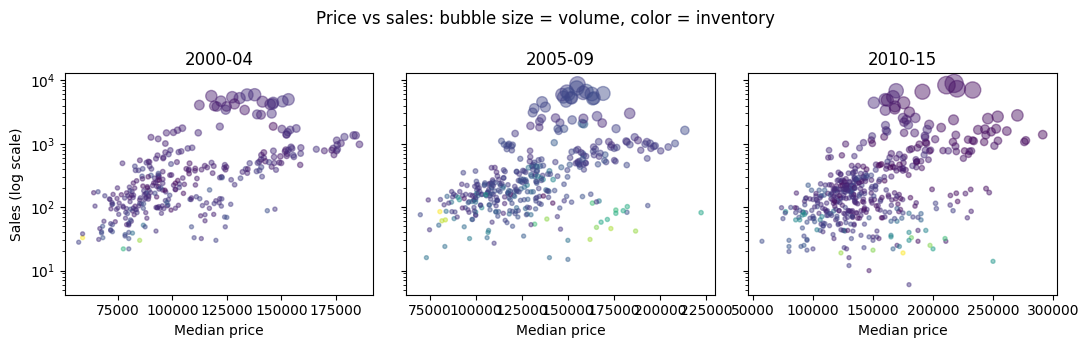

In [6]:
multi = tx.dropna(subset=numeric_columns + ["period"])
plot_data = multi.sample(1200, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharey=True)
for ax, period in zip(axes, tx["period"].cat.categories):
    part = plot_data[plot_data["period"] == period]
    sizes = 8 + 35 * part["volume"] / plot_data["volume"].quantile(0.95)
    ax.scatter(part["median"], part["sales"], s=sizes,
               c=part["inventory"], cmap="viridis", alpha=0.45)
    ax.set(title=str(period), xlabel="Median price", yscale="log")
axes[0].set_ylabel("Sales (log scale)")
fig.suptitle("Price vs sales: bubble size = volume, color = inventory")
plt.tight_layout()
plt.show()


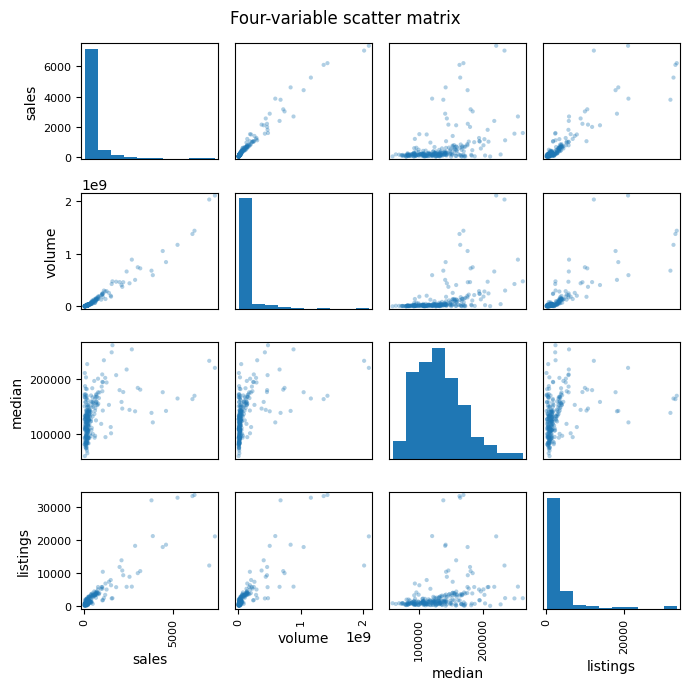

In [7]:
from pandas.plotting import scatter_matrix, parallel_coordinates

features = ["sales", "volume", "median", "listings", "inventory"]
pair_sample = multi[features[:4]].sample(250, random_state=42)
scatter_matrix(pair_sample, figsize=(7, 7), diagonal="hist", alpha=0.35)
plt.suptitle("Four-variable scatter matrix")
plt.tight_layout()
plt.show()


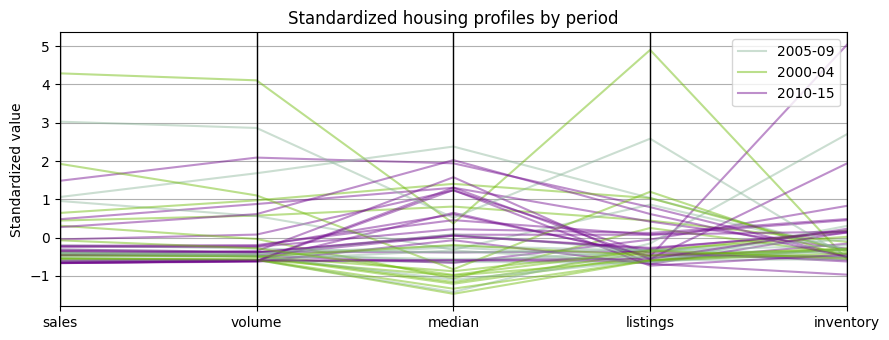

In [8]:
parallel = multi[features + ["period"]].sample(45, random_state=42).copy()
parallel[features] = (parallel[features] - parallel[features].mean()) / parallel[features].std()
plt.figure(figsize=(9, 3.5))
parallel_coordinates(parallel, "period", features, alpha=0.45)
plt.title("Standardized housing profiles by period")
plt.ylabel("Standardized value")
plt.tight_layout()
plt.show()


**Outcome:** volume and sales rise together across panels. The later years cover a wider price range; parallel lines show how the measurements vary across individual records.

## Assessment 6: AirPassengers time series

These are the 144 monthly passenger counts from R's built-in AirPassengers dataset. The series is in thousands.

Months: 144 | First: 112 | Last: 432


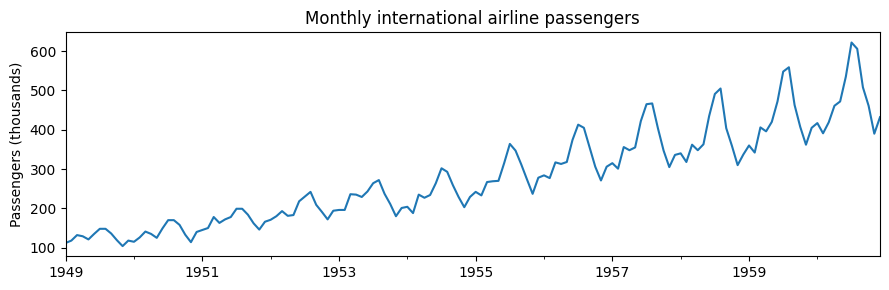

In [9]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

air_values = np.array([
    112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118,
    115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140,
    145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166,
    171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194,
    196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201,
    204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229,
    242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278,
    284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306,
    315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336,
    340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337,
    360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405,
    417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432,
])
air = pd.Series(air_values,
                index=pd.date_range("1949-01-01", periods=144, freq="MS"),
                name="Passengers (thousands)")
print("Months:", len(air), "| First:", air.iloc[0], "| Last:", air.iloc[-1])
air.plot(figsize=(9, 3), title="Monthly international airline passengers")
plt.ylabel("Passengers (thousands)")
plt.tight_layout()
plt.show()


1961 forecast (thousands):
            Forecast  Lower 95%  Upper 95%
1961-01-01       451        420        484
1961-02-01       426        392        462
1961-03-01       479        437        525
1961-04-01       493        446        545
1961-05-01       510        457        568
1961-06-01       584        520        655
1961-07-01       671        593        758
1961-08-01       668        587        760
1961-09-01       558        488        639
1961-10-01       498        432        573
1961-11-01       430        371        498
1961-12-01       477        410        556


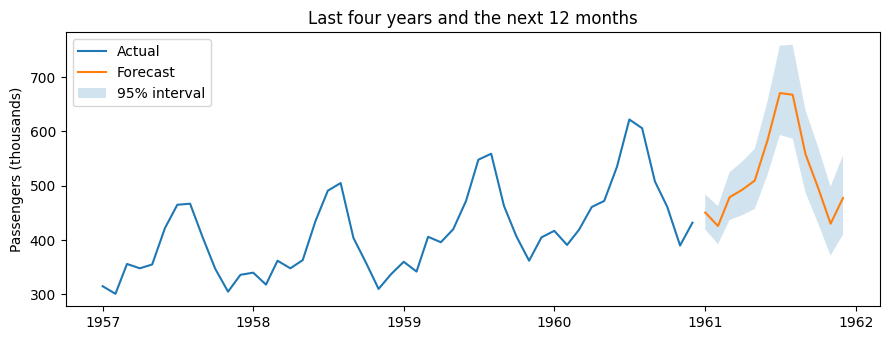

In [10]:
model = SARIMAX(np.log(air), order=(0, 1, 1),
                seasonal_order=(0, 1, 1, 12),
                enforce_stationarity=False,
                enforce_invertibility=False).fit(disp=False)
prediction = model.get_forecast(steps=12)
forecast = np.exp(prediction.predicted_mean)
interval = np.exp(prediction.conf_int())
forecast_table = pd.DataFrame({
    "Forecast": forecast.round().astype(int),
    "Lower 95%": interval.iloc[:, 0].round().astype(int),
    "Upper 95%": interval.iloc[:, 1].round().astype(int)
})
print("1961 forecast (thousands):")
print(forecast_table.to_string())

plt.figure(figsize=(9, 3.5))
plt.plot(air.iloc[-48:], label="Actual")
plt.plot(forecast, label="Forecast")
plt.fill_between(forecast.index, interval.iloc[:, 0].to_numpy(),
                 interval.iloc[:, 1].to_numpy(), alpha=0.2, label="95% interval")
plt.title("Last four years and the next 12 months")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.tight_layout()
plt.show()


**Outcome:** the data rises over time and repeats a yearly seasonal pattern. The 1961 forecast continues both patterns.

## Assessment 7: univariate, bivariate, and grouped EDA

Summarize the shape of sales, compare periods, and measure relationships with other variables.

Sales statistics:
Mean                   549.56
Median                 169.00
Standard deviation    1110.74
Skewness                 3.89
Excess kurtosis         16.44

Sales by period:
         count   mean  median
period                       
2000-04   2336  525.0   169.0
2005-09   2624  580.6   180.0
2010-15   3074  541.8   160.0

Correlations with sales:
sales        1.000
volume       0.981
median       0.345
listings     0.921
inventory   -0.193


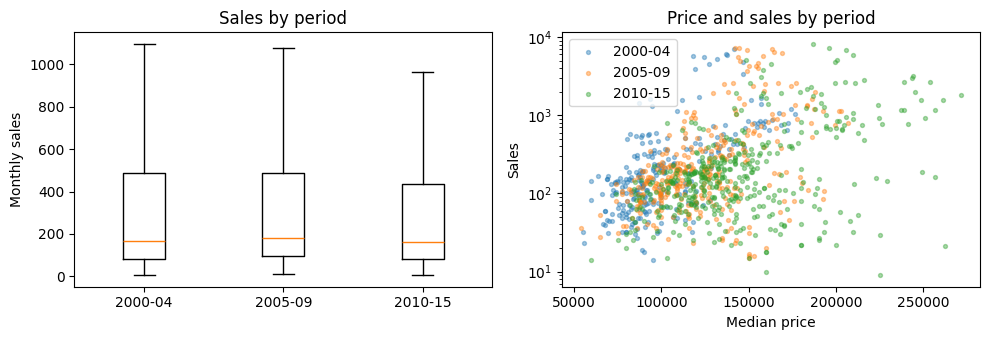

In [11]:
print("Sales statistics:")
print(pd.Series({
    "Mean": sales.mean(), "Median": sales.median(),
    "Standard deviation": sales.std(), "Skewness": sales.skew(),
    "Excess kurtosis": sales.kurt()
}).round(2).to_string())
print("\nSales by period:")
print(tx.groupby("period", observed=True)["sales"]
        .agg(["count", "mean", "median"]).round(1).to_string())
print("\nCorrelations with sales:")
print(tx[numeric_columns].corr()["sales"].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
groups = [tx.loc[tx["period"] == p, "sales"].dropna()
          for p in tx["period"].cat.categories]
axes[0].boxplot(groups, tick_labels=tx["period"].cat.categories, showfliers=False)
axes[0].set(title="Sales by period", ylabel="Monthly sales")
point_data = tx.dropna(subset=["median", "sales"]).sample(1000, random_state=42)
for period in tx["period"].cat.categories:
    part = point_data[point_data["period"] == period]
    axes[1].scatter(part["median"], part["sales"], s=8, alpha=0.4, label=period)
axes[1].set(title="Price and sales by period", xlabel="Median price",
            ylabel="Sales", yscale="log")
axes[1].legend()
plt.tight_layout()
plt.show()


**Outcome:** sales are strongly right-skewed. Sales relate very strongly to volume and listings, moderately to price, and weakly negatively to inventory.

## Assessment 8: K-means and hierarchical clustering

Standardize seven numeric features before clustering. K-means uses every complete row; the dendrogram uses a 300-row sample so it stays quick and readable.

Complete housing records: 7126
K-means cluster sizes (K=3): [ 400 3911 2815]
Ward cluster sizes (300-row sample): [ 16  17 267]


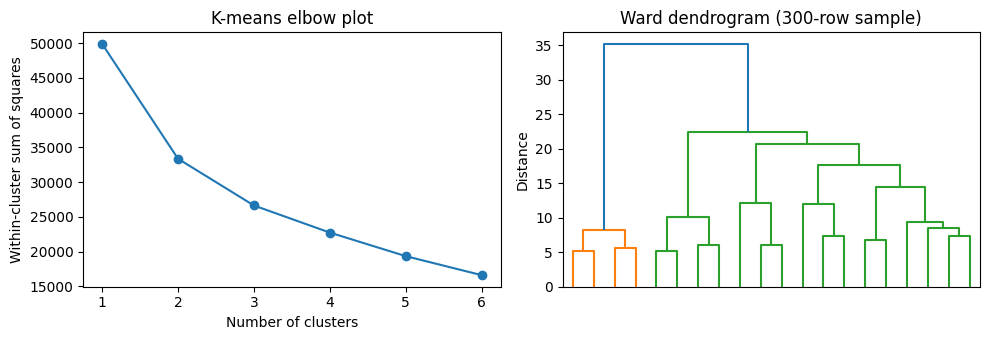

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

cluster_features = ["year", "month", "sales", "volume",
                    "median", "listings", "inventory"]
cluster_data = tx[cluster_features].dropna()
scaled_housing = StandardScaler().fit_transform(cluster_data)
inertia = []
for k in range(1, 7):
    result = KMeans(n_clusters=k, random_state=42, n_init=10).fit(scaled_housing)
    inertia.append(result.inertia_)
    if k == 3:
        kmeans_labels = result.labels_
print("Complete housing records:", len(cluster_data))
print("K-means cluster sizes (K=3):", np.bincount(kmeans_labels))

sample_index = np.random.default_rng(42).choice(len(scaled_housing), 300,
                                                replace=False)
tree = linkage(scaled_housing[sample_index], method="ward")
ward_labels = fcluster(tree, 3, criterion="maxclust")
print("Ward cluster sizes (300-row sample):", np.bincount(ward_labels)[1:])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(range(1, 7), inertia, marker="o")
axes[0].set(title="K-means elbow plot", xlabel="Number of clusters",
            ylabel="Within-cluster sum of squares")
dendrogram(tree, truncate_mode="lastp", p=20, no_labels=True, ax=axes[1])
axes[1].set(title="Ward dendrogram (300-row sample)", ylabel="Distance")
plt.tight_layout()
plt.show()


**Outcome:** scaling makes the seven features comparable. A three-cluster solution gives a simple grouping of housing records; Ward's method gives a second view of that grouping.

## Assessment 9: principal component analysis of mtcars

Use the same six columns as the R assignment. The 32 automobile rows are included below, so this section needs no download.

In [13]:
from io import StringIO
from sklearn.decomposition import PCA

cars_csv = """"","mpg","disp","hp","drat","wt","qsec"
"Mazda RX4",21,160,110,3.9,2.62,16.46
"Mazda RX4 Wag",21,160,110,3.9,2.875,17.02
"Datsun 710",22.8,108,93,3.85,2.32,18.61
"Hornet 4 Drive",21.4,258,110,3.08,3.215,19.44
"Hornet Sportabout",18.7,360,175,3.15,3.44,17.02
"Valiant",18.1,225,105,2.76,3.46,20.22
"Duster 360",14.3,360,245,3.21,3.57,15.84
"Merc 240D",24.4,146.7,62,3.69,3.19,20
"Merc 230",22.8,140.8,95,3.92,3.15,22.9
"Merc 280",19.2,167.6,123,3.92,3.44,18.3
"Merc 280C",17.8,167.6,123,3.92,3.44,18.9
"Merc 450SE",16.4,275.8,180,3.07,4.07,17.4
"Merc 450SL",17.3,275.8,180,3.07,3.73,17.6
"Merc 450SLC",15.2,275.8,180,3.07,3.78,18
"Cadillac Fleetwood",10.4,472,205,2.93,5.25,17.98
"Lincoln Continental",10.4,460,215,3,5.424,17.82
"Chrysler Imperial",14.7,440,230,3.23,5.345,17.42
"Fiat 128",32.4,78.7,66,4.08,2.2,19.47
"Honda Civic",30.4,75.7,52,4.93,1.615,18.52
"Toyota Corolla",33.9,71.1,65,4.22,1.835,19.9
"Toyota Corona",21.5,120.1,97,3.7,2.465,20.01
"Dodge Challenger",15.5,318,150,2.76,3.52,16.87
"AMC Javelin",15.2,304,150,3.15,3.435,17.3
"Camaro Z28",13.3,350,245,3.73,3.84,15.41
"Pontiac Firebird",19.2,400,175,3.08,3.845,17.05
"Fiat X1-9",27.3,79,66,4.08,1.935,18.9
"Porsche 914-2",26,120.3,91,4.43,2.14,16.7
"Lotus Europa",30.4,95.1,113,3.77,1.513,16.9
"Ford Pantera L",15.8,351,264,4.22,3.17,14.5
"Ferrari Dino",19.7,145,175,3.62,2.77,15.5
"Maserati Bora",15,301,335,3.54,3.57,14.6
"Volvo 142E",21.4,121,109,4.11,2.78,18.6"""
cars = pd.read_csv(StringIO(cars_csv), index_col=0)
car_features = ["mpg", "disp", "hp", "drat", "wt", "qsec"]
print("Cars:", len(cars))
print(cars[car_features].describe().loc[["mean", "std", "min", "max"]].round(2).to_string())


Cars: 32
        mpg    disp      hp  drat    wt   qsec
mean  20.09  230.72  146.69  3.60  3.22  17.85
std    6.03  123.94   68.56  0.53  0.98   1.79
min   10.40   71.10   52.00  2.76  1.51  14.50
max   33.90  472.00  335.00  4.93  5.42  22.90


Component  Variance %  Cumulative %
      PC1       69.79         69.79
      PC2       19.14         88.93
      PC3        5.56         94.48
      PC4        2.57         97.05
      PC5        2.08         99.13
      PC6        0.87        100.00

Components needed for at least 80% variance: 2

PC1 and PC2 loadings:
       PC1   PC2
mpg  -0.46 -0.06
disp  0.47  0.06
hp    0.43 -0.36
drat -0.37 -0.44
wt    0.44  0.30
qsec -0.25  0.76


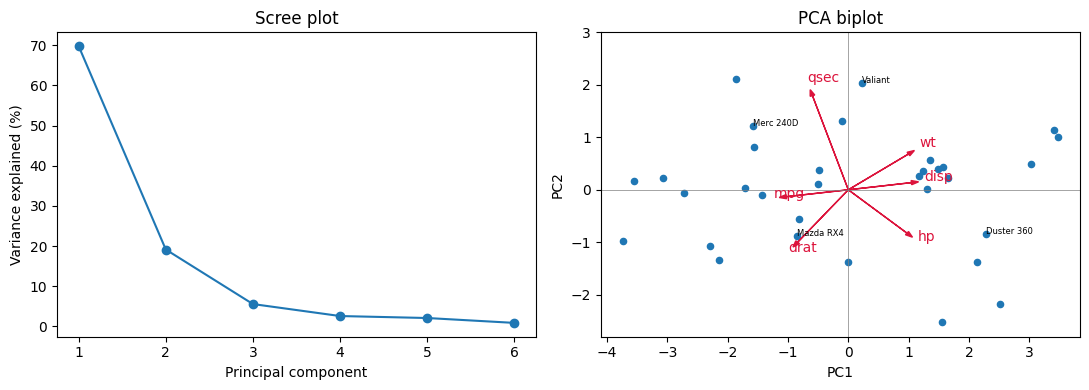

In [14]:
car_scaled = StandardScaler().fit_transform(cars[car_features])
pca = PCA().fit(car_scaled)
percent = pca.explained_variance_ratio_ * 100
cumulative = np.cumsum(percent)
needed = np.searchsorted(cumulative, 80) + 1
variance_table = pd.DataFrame({
    "Component": [f"PC{i}" for i in range(1, 7)],
    "Variance %": percent.round(2),
    "Cumulative %": cumulative.round(2)
})
loadings = pd.DataFrame(pca.components_[:2].T, index=car_features,
                        columns=["PC1", "PC2"])
print(variance_table.to_string(index=False))
print(f"\nComponents needed for at least 80% variance: {needed}")
print("\nPC1 and PC2 loadings:")
print(loadings.round(2).to_string())

scores = pca.transform(car_scaled)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, 7), percent, marker="o")
axes[0].set(title="Scree plot", xlabel="Principal component",
            ylabel="Variance explained (%)", xticks=range(1, 7))
axes[1].scatter(scores[:, 0], scores[:, 1], s=20)
for i in [0, 5, 6, 7]:
    car_name = cars.index[i]
    axes[1].annotate(car_name, scores[i, :2], fontsize=6)
for name in car_features:
    dx, dy = loadings.loc[name] * 2.5
    axes[1].arrow(0, 0, dx, dy, color="crimson",
                  head_width=0.08, length_includes_head=True)
    axes[1].text(dx * 1.08, dy * 1.08, name, color="crimson")
axes[1].axhline(0, color="grey", lw=0.5)
axes[1].axvline(0, color="grey", lw=0.5)
axes[1].set(title="PCA biplot", xlabel="PC1", ylabel="PC2")
axes[1].set_ylim(-2.8, 3)
plt.tight_layout()
plt.show()


**Outcome:** PC1 and PC2 together explain about 88.93% of the variation, so two components are enough to pass the 80% target. Weight, displacement, and horsepower point together; miles per gallon points roughly opposite them.

## Final summary

Across nine assessments, we joined and scaled data, cleaned missing values, checked distributions and relationships, examined several variables at once, forecast a monthly series, grouped similar records, and reduced six car variables to two principal components.